# Trace photons
A look inside `simulation_tools/trace_photons.py`: what a CORSIKA file looks like, which numbers the script changes on
its way to sim_telarray, and what sim_telarray then sees.

sim_telarray runs with `bypass_optics = 1`, so it skips its own optics and treats each photon bunch's (x, y) as where it
lands on the camera. `trace_photons.py` traces CORSIKA's bunches through the PANOSETI lens (`optical_model.py`) and
overwrites their (x, y) with where they land, so sim_telarray's camera sees the lens's image.

This runs the script's own functions on one telescope array's photons from a CORSIKA file of an existing production.

## Imports

In [1]:
import io
import json
import struct
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import zstandard
from matplotlib import pyplot as plt

sys.path.insert(0, str(Path("../simulation_tools").resolve()))
import trace_photons as tp

## Settings

In [2]:
PRODUCTION = Path("~/simulations/sim_output/gamma_pointlike").expanduser()
RUN = "gamma_pointlike_run000001"
CORSIKA_FILE = PRODUCTION / "corsika" / f"{RUN}.corsika.zst"
POINTING_FILE = PRODUCTION / "simtel" / "v1" / f"{RUN}.pointing.json" # the pointing run_simulation.py traced with
SEED = 1 # for the wavelengths

pointing = json.loads(POINTING_FILE.read_text())
print(f"pointing theta={pointing['theta']:g}, phi={pointing['phi']:g} deg, optics {pointing['optics']}")

pointing theta=20, phi=191.03 deg, optics {'thick_lens': False, 'focal_offset': 0.0}


## 1. The file is a sequence of boxes
A CORSIKA IACT file is an *eventio* stream: a flat sequence of objects ("boxes"). Each starts with a 4-byte sync marker
and a 12-byte header (16 for very long objects) giving its type and content length, then that many bytes of content.
Some boxes, like the telescope data (1204), hold more boxes inside.

`boxes()` reads them the way `trace_photons.patch_stream()` does.

In [3]:
NAMES = {1200: "run header", 1201: "telescope definition", 1202: "event header", 1203: "array offsets",
         1204: "telescope data", 1205: "photon bunches", 1209: "event end", 1210: "run end", 1211: "longitudinal",
         1212: "input card", 1216: "atmospheric profile"}


def boxes(stream):
    """(type, header bytes incl. sync, content bytes) for each top-level eventio object in stream."""
    while True:
        sync = stream.read(4)
        if not sync:
            return
        head = tp._read(stream, 12)
        if struct.unpack_from("<I", head)[0] & (1 << 17):
            head += tp._read(stream, 4)
        object_type, _, length, _ = tp._header(head)
        yield object_type, sync + head, tp._read(stream, length)


def sub_boxes(content):
    """(type, header bytes, content bytes) for each object inside a telescope data (1204) object."""
    offset = 0
    while offset < len(content):
        sub_type, _, sub_length, sub_size = tp._header(content, offset)
        yield sub_type, content[offset:offset + sub_size], content[offset + sub_size:offset + sub_size + sub_length]
        offset += sub_size + sub_length


def read_corsika(path):
    return list(boxes(zstandard.ZstdDecompressor().stream_reader(open(path, "rb"))))


objects = read_corsika(CORSIKA_FILE)
pd.DataFrame([(t, NAMES.get(t, "?"), len(content)) for t, _, content in objects[:20]],
             columns=["type", "name", "content bytes"])

,type,name,content bytes
0,1200,run header,1096
1,1212,input card,1076
2,1216,atmospheric profile,1800
3,1201,telescope definition,116
4,1202,event header,1096
5,1203,array offsets,48
6,1211,longitudinal,1708
7,1204,telescope data,296
8,1204,telescope data,5640
9,1204,telescope data,776


The run starts with its header, input card, atmosphere and the telescope positions (1201). Then for each shower: its
event header (1202), the array's core positions (1203), the longitudinal profile (1211), one telescope data box (1204)
per core position (CORSIKA reuses each shower at several cores, `CSCAT`), and an event end (1209).

Inside a 1204 there is one photon bunch box (1205) per telescope. Its content is a 12-byte header (array, telescope,
photon sum, number of bunches) and then a table: one row per bunch, 8 float32 columns.

In [4]:
COLUMNS = ["x", "y", "cx", "cy", "time", "zem", "photons", "wavelength"] # cm, cm, -, -, ns, cm, -, nm


def photon_tables(telescope_data):
    """{telescope: (N, 8) bunch table} from one 1204 object's content."""
    tables = {}
    for sub_type, _, content in sub_boxes(telescope_data):
        if sub_type == tp.PHOTONS:
            _, telescope, _, n_bunches = struct.unpack_from("<hhfi", content)
            tables[telescope] = np.frombuffer(content, dtype="<f4", offset=12).reshape(n_bunches, 8)
    return tables


# the core position with the most bunches, and the boxes trace_photons needs before it
i_data = max((i for i, (t, _, _) in enumerate(objects) if t == tp.TELESCOPE_DATA),
             key=lambda i: sum(len(table) for table in photon_tables(objects[i][2]).values()))
i_header = max(i for i, (t, _, _) in enumerate(objects[:i_data]) if t == tp.EVENT_HEADER)
event_header = np.frombuffer(objects[i_header][2], dtype="<f4", offset=4)
before = photon_tables(objects[i_data][2])

print(f"shower {int(event_header[1])}, {event_header[3] * 1e-3:.2f} TeV, "
      f"wavelengths {event_header[95]:g}-{event_header[96]:g} nm")
pd.DataFrame({"bunches": {tel: len(table) for tel, table in before.items()},
              "photons": {tel: table[:, 6].sum() for tel, table in before.items()}}).rename_axis("telescope")

shower 94, 15.24 TeV, wavelengths 200-700 nm


,bunches,photons
telescope,,
0,3327,16527.113281
1,13,64.602249
2,108,535.473755
3,0,0.000000
4,0,0.000000
5,55,271.548615
6,48,237.086456


## 2. Run trace_photons on it
`patch_stream()` copies the stream box by box. It remembers the telescope heights (1201) and the wavelength range
(1202), and in each 1204 replaces the 1205 tables. Here it gets the run's first boxes, this shower's event header and
the chosen 1204, in memory instead of through the pipe to sim_telarray.

In [5]:
run_start = [box for box in objects[:i_header] if box[0] in (1200, 1212, 1216, 1201)]
stream_in = b"".join(head + content for _, head, content in run_start + [objects[i_header], objects[i_data]])

tracer = tp.PhotonTracer(pointing["theta"], pointing["phi"], pointing["optics"]["thick_lens"],
                         pointing["optics"]["focal_offset"], seed=SEED)
stream_out = io.BytesIO()
tp.patch_stream(io.BytesIO(stream_in), stream_out, tracer)
stream_out = stream_out.getvalue()
print(tracer.stats)

traced_objects = list(boxes(io.BytesIO(stream_out)))
pd.DataFrame([(NAMES[t], len(c), len(c2), h == h2, c == c2)
              for (t, h, c), (_, h2, c2) in zip(boxes(io.BytesIO(stream_in)), traced_objects)],
             columns=["box", "bytes in", "bytes out", "same header", "same content"])

{'bunches': 3551, 'vignetted': 528, 'photons_in': 17635.8243560791, 'photons_out': 4225.272741317749}


,box,bytes in,bytes out,same header,same content
0,run header,1096,1096,True,True
1,input card,1076,1076,True,True
2,atmospheric profile,1800,1800,True,True
3,telescope definition,116,116,True,True
4,event header,1096,1096,True,True
5,telescope data,113800,113800,True,False


Every box comes out the same length with the same header, so the output is still a valid CORSIKA file that
sim_telarray reads as if it came from CORSIKA. Only the telescope data changed, and inside it only the photon tables
(and each table's photon sum, in its own small header).

## 3. One telescope's table, before and after

In [6]:
after = photon_tables(traced_objects[-1][2])
TELESCOPE = max(before, key=lambda tel: len(before[tel]))
b, a = before[TELESCOPE].astype(float), after[TELESCOPE].astype(float)

print(f"telescope {TELESCOPE}, {len(b)} bunches; columns changed:",
      [column for i, column in enumerate(COLUMNS) if not np.array_equal(a[:, i], b[:, i])])
CHANGED = ["x", "y", "photons", "wavelength"]
columns = [COLUMNS.index(column) for column in CHANGED]
pd.concat({"before": pd.DataFrame(b[:8, columns], columns=CHANGED),
           "after": pd.DataFrame(a[:8, columns], columns=CHANGED)}, axis=1)

telescope 0, 3327 bunches; columns changed: ['x', 'y', 'photons', 'wavelength']


before                                        after              \
           x          y   photons wavelength            x           y   
0  -5.336626 -17.398874  4.970318        0.0 -1409.934326  279.366272   
1   8.394718  15.742161  4.937719        0.0 -1451.895874  317.526764   
2 -15.608811  12.726734  4.987321        0.0 -1423.267212  279.942963   
3 -23.869373   9.608403  4.959139        0.0   -23.869373    9.608403   
4  -2.194386  -5.558911  4.965948        0.0 -1426.715820  277.295563   
5   3.082988   1.467282  4.954017        0.0 -1414.024658  281.559052   
6 -14.599407 -11.683089  4.955087        0.0 -1425.291382  276.262604   
7   6.916025 -23.387125  4.951238        0.0     6.916025  -23.387125   

                         
    photons  wavelength  
0  0.000000  315.251984  
1  4.521278  622.864014  
2  0.000000  222.958267  
3  0.000000  620.360352  
4  0.000000  257.313080  
5  0.000000  286.687408  
6  4.544436  489.256104  
7  0.000000  282.599670

* **wavelength**: CORSIKA leaves it 0 (sim_telarray would draw it). `trace_photons` draws it from the Cherenkov
  spectrum (1/λ²) over CORSIKA's range, because the lens's refraction and transmission depend on it.
* **photons**: multiplied by the lens's (PMMA) transmission at that wavelength, 0 if the lens vignettes the bunch.
* **x, y**: before, where the bunch crosses the telescope, on the lens within its 46 cm aperture. After, not the
  camera position itself but a position chosen so that sim_telarray's bypass step (section 5) ends up at the camera
  position. That step moves each bunch ~40 m down along its direction, which at 20 deg from the zenith is ~14 m
  sideways, so the written x, y are ~14 m the other way. Vignetted bunches (photons 0) keep their x, y.
* **cx, cy, time, zem**: untouched; sim_telarray still uses the direction for the atmosphere's absorption.

## 4. Wavelengths and transmission

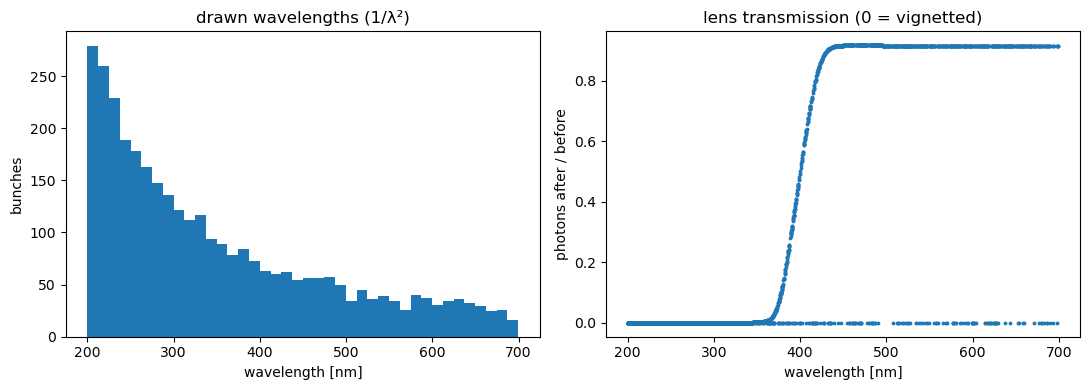

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].hist(a[:, 7], bins=40)
axs[0].set(xlabel="wavelength [nm]", ylabel="bunches", title="drawn wavelengths (1/λ²)")
axs[1].scatter(a[:, 7], a[:, 6] / b[:, 6], s=3)
axs[1].set(xlabel="wavelength [nm]", ylabel="photons after / before", title="lens transmission (0 = vignetted)")
plt.tight_layout()

## 5. Where the photons land: what sim_telarray sees
With `bypass_optics = 1` sim_telarray still does two things to each bunch: it moves it along its direction from the
telescope's height down to CORSIKA's observation level (`z_telescope` below), and it flips the sign of y. Its camera
position is then

    camera x =   bunch x + d cx
    camera y = -(bunch y + d cy),     d = z_telescope / cos(angle to vertical)

`tp.camera_to_bunch()` is the inverse of this: it writes the bunch (x, y) that sim_telarray will turn back into the
traced camera position. `bypass()` below applies sim_telarray's step to both tables.

In [8]:
telescope_definition = next(content for t, _, content in objects if t == tp.TELESCOPE_DEFINITION)
n_telescopes = struct.unpack_from("<i", telescope_definition)[0]
z_telescope = np.frombuffer(telescope_definition, dtype="<f4", count=4 * n_telescopes, offset=4).reshape(4, -1)[2]


def bypass(table, z):
    """Camera (x, y) [cm] that sim_telarray's bypass_optics gives the bunches of table."""
    cx, cy = table[:, 2], table[:, 3]
    d = z / np.sqrt(1. - cx**2 - cy**2)
    return table[:, 0] + d * cx, -(table[:, 1] + d * cy)


# check: the camera positions sim_telarray will use are the ones traced through the lens
x_traced, y_traced, valid = tracer.camera_positions(before[TELESCOPE], a[:, 7])
x_simtel, y_simtel = bypass(a, z_telescope[TELESCOPE])
print(f"telescope {TELESCOPE} at z = {z_telescope[TELESCOPE]:g} cm, {valid.sum()} of {len(valid)} bunches through the lens; "
      f"largest difference sim_telarray - traced: {np.abs(np.r_[x_simtel - x_traced, y_simtel - y_traced][np.r_[valid, valid]]).max():.1e} cm")

telescope 0 at z = 3970 cm, 2832 of 3327 bunches through the lens; largest difference sim_telarray - traced: 6.1e-05 cm


traced image centroid: (-0.37, -0.32) deg from the pointing


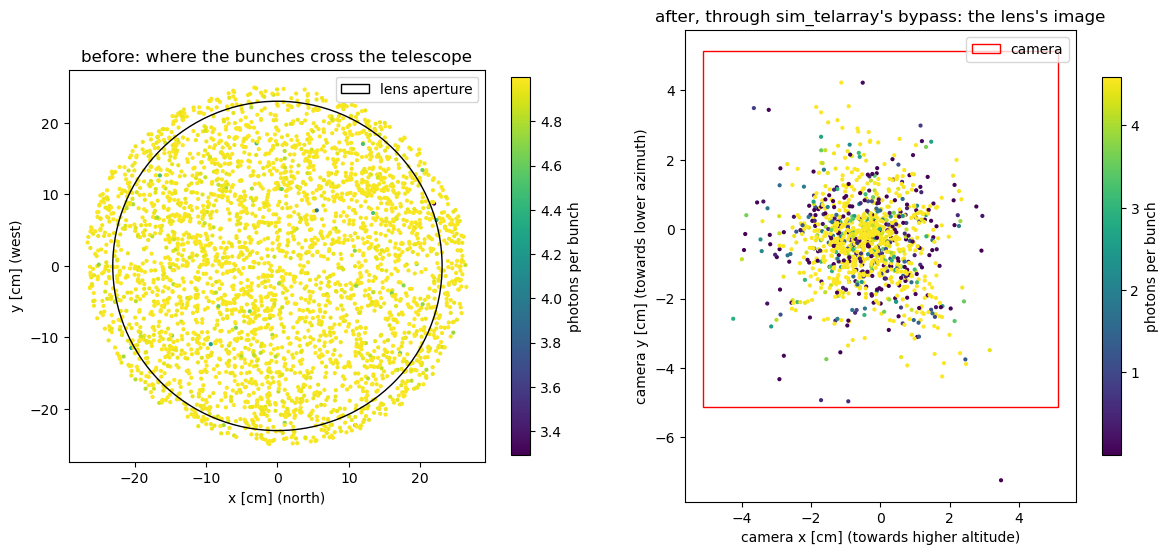

In [9]:
optics = tracer.optics
half = optics["npixel"] * optics["pixel_spacing"] / 2 # cm, camera half-width
fig, axs = plt.subplots(1, 2, figsize=(12, 5.5))
image = axs[0].scatter(b[:, 0], b[:, 1], c=b[:, 6], s=4)
axs[0].add_patch(plt.Circle((0, 0), optics["D"] / 2, fill=False, color="k", label="lens aperture"))
axs[0].set(xlabel="x [cm] (north)", ylabel="y [cm] (west)", title="before: where the bunches cross the telescope",
           aspect="equal")
plt.colorbar(image, ax=axs[0], label="photons per bunch", shrink=0.8)
x, y = bypass(a, z_telescope[TELESCOPE])
keep = a[:, 6] > 0
image = axs[1].scatter(x[keep], y[keep], c=a[keep, 6], s=4)
axs[1].add_patch(plt.Rectangle((-half, -half), 2 * half, 2 * half, fill=False, color="r", label="camera"))
axs[1].set(xlabel="camera x [cm] (towards higher altitude)", ylabel="camera y [cm] (towards lower azimuth)",
           title="after, through sim_telarray's bypass: the lens's image", aspect="equal")
plt.colorbar(image, ax=axs[1], label="photons per bunch", shrink=0.8)
for ax in axs:
    ax.legend(loc="upper right")

print(f"traced image centroid: ({np.degrees(np.average(x[keep], weights=a[keep, 6]) / optics['F']):.2f}, "
      f"{np.degrees(np.average(y[keep], weights=a[keep, 6]) / optics['F']):.2f}) deg from the pointing")
plt.tight_layout()

Before, the bunches are spread over the lens's 46 cm aperture (plus some that miss it, which the trace vignettes).
After, the lens has focused them into the shower's image on the 10 cm camera. sim_telarray then does the rest as usual:
atmospheric absorption, the sensors' detection efficiency at each bunch's wavelength, pixels, night sky background and
electronics, and writes the `.simtel.zst` file.